<H1> Financial Market Dynamics: Statistical Modelling, Econometric Analysis and Time-Series Forecasting of the S&P 500 (2016–2026) </H1>

<B1> **Research question:** To what extent can financial market indicators explain fluctuations in S&P 500 returns, and how effectively can historical market data be used to forecast future market movements? </B1>

<B1> **Phase 1: Data Acquisition, Integration and Preparation**  </B1>

<B1> **Name:** Syed Zaid </B1> 

<B1> **Dataset Source:** Federal Reserve Bank of St. Louis – Federal Reserve Economic Data (FRED) </B1> 

<B1> **Domain:** Financial Markets, Stock Market Volatility and Macroeconomic Indicators </B1> 

<B1> **Study Period:** October 2016 – October 2026. </B1>


<H2> 1. Import all the Libraries </H2>

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy import stats

from pathlib import Path

# Locate the project root
current_dir = Path.cwd().resolve()

if (current_dir / "Data").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "Data").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Could not locate the project root. "
        "Run the notebook from the project root or Notebooks folder."
    )

# Define dataset directories
RAW_DATA_DIR = PROJECT_ROOT / "Data" / "Raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "Data" / "Processed"

# Ensure directories exist
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_ROOT)

Project directory: C:\Users\reshma begum\Desktop\Projects\sp500-financial-market-analysis


<H2> 2. Master Dataset Creation </H2>

In [2]:
base_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id="

series = {
    "SP500_Close": "SP500",
    "VIX": "VIXCLS",
    "Treasury_10Y": "DGS10",
    "Brent_Oil": "DCOILBRENTEU",
    "Fed_Rate": "DFF"
}

data = {}

for column, series_id in series.items():

    url = base_url + series_id

    df = pd.read_csv(url)

    df.columns = ["Date", column]

    data[column] = df

In [3]:
dataset = data["SP500_Close"]

for column in list(data.keys())[1:]:

    dataset = pd.merge(
        dataset,
        data[column],
        on="Date",
        how="left"
    )

In [4]:
dataset["Date"] = pd.to_datetime(dataset["Date"])

dataset = dataset[
    dataset["Date"] >= "2016-01-01"
]

dataset = dataset.reset_index(drop=True)

dataset.head()

,Date,SP500_Close,VIX,Treasury_10Y,Brent_Oil,Fed_Rate
0,2025-11-17,6672.41,22.38,4.13,63.16,3.88
1,2025-11-18,6617.32,24.69,4.12,64.86,3.88
2,2025-11-19,6642.16,23.66,4.13,63.78,3.88
3,2025-11-20,6538.76,26.42,4.10,63.64,3.88
4,2025-11-21,6602.99,23.43,4.06,62.78,3.88


In [5]:
raw_path = RAW_DATA_DIR / "Financial_dataset_Raw.csv"

dataset.to_csv(raw_path, index=False)

print("Raw dataset saved successfully!")
print("Location:", raw_path)

Raw dataset saved successfully!
Location: C:\Users\reshma begum\Desktop\Projects\sp500-financial-market-analysis\Data\Raw\Financial_dataset_Raw.csv


## Data Collection Methodology

### A. Objective

Before beginning the data preprocessing and exploratory data analysis, it was necessary to construct a consolidated dataset containing multiple US financial market indicators.

The selected financial indicators were available as separate time-series datasets through the Federal Reserve Economic Data (FRED) platform, maintained by the Federal Reserve Bank of St. Louis. Since the objective of the project was to examine the relationship between S&P 500 returns and changes in market volatility, it was necessary to bring the relevant financial indicators together into a single dataset.

Rather than relying on an already compiled dataset, I created a master dataset by independently retrieving and combining five individual financial time series.

### B. Data Sources
**Database Website:** https://fred.stlouisfed.org/

The five financial indicators were obtained directly from FRED using their respective series identifiers.

| Financial Indicator | FRED Series ID | Description |
|---|---|---|
| S&P 500 Closing Price | SP500 | Daily closing value of the S&P 500 index. |
| CBOE Volatility Index (VIX) | VIXCLS | Daily measure of expected stock market volatility. |
| 10-Year Treasury Yield | DGS10 | Market yield on US Treasury securities with a 10-year maturity. |
| Brent Crude Oil Price | DCOILBRENTEU | Daily price of Brent crude oil. |
| Effective Federal Funds Rate | DFF | Effective interest rate in the US federal funds market. |

**Source:** Federal Reserve Economic Data (FRED), Federal Reserve Bank of St. Louis.

### C. Reason for Creating a Master Dataset

The five indicators were maintained as separate datasets, with potentially different observation availability and reporting calendars.

Working with separate files would have made it more difficult to conduct comparative analysis and examine the relationships between the variables. Therefore, a consolidated dataset was created by combining the individual series using their common Date column.

The S&P 500 dataset was selected as the base dataset because it was the primary variable of interest in the project. The remaining four datasets were merged into it using left joins.

This approach retained the dates available in the S&P 500 dataset while attaching corresponding observations from the other financial indicators wherever matching dates were available.

Importantly, a left join was selected rather than an inner join because an inner join would have discarded dates that did not have matching observations across all five datasets. Retaining the base dates allowed missing observations to remain identifiable and be examined during the subsequent preprocessing stage.

### D. Dataset Integration and Processing

The data collection and integration process was implemented using Python, primarily with the Pandas library.

First, each FRED series was retrieved separately using its respective series identifier. The downloaded data was stored in individual DataFrames, with the Date column and the corresponding financial indicator.

Next, the S&P 500 dataset was selected as the base DataFrame. The other four datasets were successively merged with it using the Date column as the common key.

The resulting dataset was then processed by converting the Date column into a datetime data type. Observations before 1 January 2016 were excluded to establish the selected study period. Finally, the index was reset and the consolidated dataset was exported as a CSV file.


The resulting master dataset was saved as:

**Financial_dataset_Raw.csv**


### E. Significance of the Process

Creating the master dataset was an important preliminary stage of the project. It provided a unified structure for analysing multiple financial indicators over a common study period.

It also introduced practical experience with programmatic data retrieval, dataset integration, date-based merging and CSV export using Python.

The process demonstrated how AI-assisted learning can help extend the application of programming techniques beyond the formal course syllabus, while the resulting data and subsequent analysis remain subject to inspection and verification.

<H2> 3. Loading the Dataset </H2>

In [6]:
df = pd.read_csv(RAW_DATA_DIR / "Financial_dataset_Raw.csv")

print("Raw dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Raw dataset loaded successfully!
Dataset shape: (261, 6)


,Date,SP500_Close,VIX,Treasury_10Y,Brent_Oil,Fed_Rate
0,2025-11-17,6672.41,22.38,4.13,63.16,3.88
1,2025-11-18,6617.32,24.69,4.12,64.86,3.88
2,2025-11-19,6642.16,23.66,4.13,63.78,3.88
3,2025-11-20,6538.76,26.42,4.10,63.64,3.88
4,2025-11-21,6602.99,23.43,4.06,62.78,3.88


<H2> 4. Checking the Dimensions of the Dataset </H2>

In [7]:
df.shape

(261, 6)

### Interpretation

The dataset contains 2,607 rows and 6 columns. Each row represents a dated observation, while the columns contain the date and five financial market indicators.
This establishes the initial size of the dataset before preprocessing.

<H2> 5. Inspecting Data Types and Column Information </H2>

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 261 entries, 0 to 260
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          261 non-null    object 
 1   SP500_Close   251 non-null    float64
 2   VIX           257 non-null    float64
 3   Treasury_10Y  249 non-null    float64
 4   Brent_Oil     250 non-null    float64
 5   Fed_Rate      260 non-null    float64
dtypes: float64(5), object(1)
memory usage: 12.4+ KB


In [9]:
df.dtypes

Date             object
SP500_Close     float64
VIX             float64
Treasury_10Y    float64
Brent_Oil       float64
Fed_Rate        float64
dtype: object

### Interpretation

The dataset contains 2,608 entries across six columns.

The five financial indicators are stored as numerical variables with the float64 data type. However, the Date column is stored as an object rather than a datetime variable.

The non-null counts also indicate missing observations in four financial indicators:

- SP500_Close: 2,512 non-null observations.
- VIX: 2,545 non-null observations.
- Treasury_10Y: 2,498 non-null observations.
- Brent_Oil: 2,534 non-null observations.
- Fed_Rate: 2,608 non-null observations.

The Federal Funds Rate is the only variable without missing observations.

<H2> 6. Summary Statistics of Numerical Columns </H2>

In [10]:
df.describe()

,SP500_Close,VIX,Treasury_10Y,Brent_Oil,Fed_Rate
count,251.000000,257.000000,249.000000,250.000000,260.000000
mean,7243.411912,18.095097,4.494217,92.241240,3.691192
std,396.670398,3.363838,0.341707,21.892969,0.104625
min,6343.720000,13.470000,3.970000,59.930000,3.620000
25%,6881.465000,15.810000,4.210000,70.720000,3.630000
50%,7365.460000,17.160000,4.440000,92.400000,3.640000
75%,7600.230000,19.120000,4.690000,113.355000,3.640000
max,7818.930000,31.050000,5.310000,138.210000,3.890000


### Interpretation

The descriptive statistics provide an overview of the distribution and range of the financial indicators.

The S&P 500 closing price has a mean of approximately 4,201.75 and a median of 3,992.47, with values ranging from 2,085.18 to 7,818.93.

The VIX has a mean of approximately 18.64 and a median of 16.96, with a maximum value of 82.69.

The 10-Year Treasury yield has a mean of approximately 2.93%, while the Brent crude oil price has a mean of approximately 72.27.

The Federal Funds Rate has a mean of approximately 2.46%, with values ranging from 0.04% to 5.33%.

The standard deviations indicate that the variables have different levels of variation over the study period.

<h2> 7. Check missing values </h2>

In [11]:
df.isnull().sum()

Date             0
SP500_Close     10
VIX              4
Treasury_10Y    12
Brent_Oil       11
Fed_Rate         1
dtype: int64

### Interpretation

The missing value analysis identified incomplete observations in four of the five financial indicators.

The number of missing values in each column is:

- SP500_Close: 96
- VIX: 63
- Treasury_10Y: 110
- Brent_Oil: 74
- Fed_Rate: 0

A total of 152 rows contain at least one missing value.

The 10-Year Treasury yield has the highest number of missing observations, while the Federal Funds Rate has complete coverage across the dataset.

The missing observations occur across the study period rather than being restricted to a single date range.

<h2> 8. Inspect rows with missing values </h2>

In [12]:
missing_rows = df[df.isnull().any(axis=1)]

print("Number of missing rows:", len(missing_rows))
print("Start date of missing rows:", missing_rows['Date'].min())
print("End date of missing rows:", missing_rows['Date'].max())

missing_rows.head(10)

Number of missing rows: 19
Start date of missing rows: 2025-11-27
End date of missing rows: 2026-11-16


,Date,SP500_Close,VIX,Treasury_10Y,Brent_Oil,Fed_Rate
8,2025-11-27,NaN,17.21,NaN,64.18,3.88
28,2025-12-25,NaN,NaN,NaN,NaN,3.64
29,2025-12-26,6929.94,13.60,4.14,NaN,3.64
33,2026-01-01,NaN,NaN,NaN,NaN,3.64
45,2026-01-19,NaN,18.84,NaN,66.91,3.64
65,2026-02-16,NaN,21.20,NaN,70.81,3.64
99,2026-04-03,NaN,NaN,4.35,NaN,3.64
100,2026-04-06,6611.83,24.17,4.34,NaN,3.64
120,2026-05-04,7200.75,18.29,4.45,NaN,3.64
135,2026-05-25,NaN,16.59,NaN,NaN,3.62


<h2> 9. Investigate missing values by column </h2>

In [13]:
missing_rows.isnull().sum()

Date             0
SP500_Close     10
VIX              4
Treasury_10Y    12
Brent_Oil       11
Fed_Rate         1
dtype: int64

In [14]:
missing_rows.isnull().sum(axis=1).value_counts().sort_index()

1    8
2    6
3    2
4    3
Name: count, dtype: int64

<h2> 10. Convert Date to datetime </h2>

In [15]:
df['Date'] = pd.to_datetime(df['Date'])
df['Date'].dtype

dtype('<M8[ns]')

### Interpretation

The Date column was successfully converted from object format to datetime64[ns].

The conversion allows Pandas to recognise the observations as dates rather than ordinary text values.

No changes were made to the actual date values.

<h2> 11. Check for duplicate records </h2>

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df['Date'].duplicated().sum()

np.int64(0)

### Interpretation

The duplicate check identified zero completely duplicated rows.

A separate check of the Date column also identified zero duplicate dates.

Therefore, the dataset does not contain repeated complete records or multiple observations assigned to the same date.

<h2> 12. Sort observations chronologically </h2>

In [18]:
df = df.sort_values(by='Date').reset_index(drop=True)

### Interpretation

The dataset was successfully arranged in ascending chronological order, beginning with the earliest observation and ending with the latest observation.

The DataFrame index was also reset after sorting to maintain a sequential index.

<h2> 13. Feature Engineering: </h2>

<h3> A. Calculate S&P 500 daily returns </h3>

<b1> Our dependent variable is the daily percentage return of the S&P 500.

Formula:

$$ R_t = \left(\frac{P_t-P_{t-1}}{P_{t-1}}\right)\times100 $$

Where:

\(P_t\) = Current trading day's closing price.
\(P_{t-1}\) = Previous trading day's closing price. </b1>

In [19]:
df['SP500_Return'] = df['SP500_Close'].pct_change(fill_method=None) * 100
df[['Date', 'SP500_Close', 'SP500_Return']].head(10)

,Date,SP500_Close,SP500_Return
0,2025-11-17,6672.41,NaN
1,2025-11-18,6617.32,-0.825639
2,2025-11-19,6642.16,0.375379
3,2025-11-20,6538.76,-1.556723
4,2025-11-21,6602.99,0.982296
5,2025-11-24,6705.12,1.546724
6,2025-11-25,6765.88,0.906173
7,2025-11-26,6812.61,0.690671
8,2025-11-27,NaN,NaN
9,2025-11-28,6849.09,NaN


<h3> B. Create the VIX change variable </h3>

In [20]:
df['VIX_Change'] = df['VIX'].diff()
df[['Date', 'VIX', 'VIX_Change']].head(10)

,Date,VIX,VIX_Change
0,2025-11-17,22.38,NaN
1,2025-11-18,24.69,2.31
2,2025-11-19,23.66,-1.03
3,2025-11-20,26.42,2.76
4,2025-11-21,23.43,-2.99
5,2025-11-24,20.52,-2.91
6,2025-11-25,18.56,-1.96
7,2025-11-26,17.19,-1.37
8,2025-11-27,17.21,0.02
9,2025-11-28,16.35,-0.86


<h3> C. Calculate Treasury yield changes </h3>

In [21]:
df['Treasury_10Y_Change'] = df['Treasury_10Y'].diff()
df[['Date', 'Treasury_10Y', 'Treasury_10Y_Change']].head(10)


,Date,Treasury_10Y,Treasury_10Y_Change
0,2025-11-17,4.13,NaN
1,2025-11-18,4.12,-0.01
2,2025-11-19,4.13,0.01
3,2025-11-20,4.10,-0.03
4,2025-11-21,4.06,-0.04
5,2025-11-24,4.04,-0.02
6,2025-11-25,4.01,-0.03
7,2025-11-26,4.00,-0.01
8,2025-11-27,NaN,NaN
9,2025-11-28,4.02,NaN


<h3> D. Calculate Brent Oil daily returns </h3>

In [22]:
df['Brent_Oil_Return'] = df['Brent_Oil'].pct_change(fill_method=None) * 100
df[['Date', 'Brent_Oil', 'Brent_Oil_Return']].head(10)

,Date,Brent_Oil,Brent_Oil_Return
0,2025-11-17,63.16,NaN
1,2025-11-18,64.86,2.691577
2,2025-11-19,63.78,-1.665125
3,2025-11-20,63.64,-0.219505
4,2025-11-21,62.78,-1.351351
5,2025-11-24,64.83,3.265371
6,2025-11-25,63.99,-1.295696
7,2025-11-26,64.81,1.281450
8,2025-11-27,64.18,-0.972072
9,2025-11-28,64.07,-0.171393


<h3> E. Calculate Federal Funds Rate Changes </h3>

In [23]:
# Calculate Federal Funds Rate Changes

df['Fed_Rate_Change'] = df['Fed_Rate'].diff()

df[['Date', 'Fed_Rate', 'Fed_Rate_Change']].head(100)

,Date,Fed_Rate,Fed_Rate_Change
0,2025-11-17,3.88,NaN
1,2025-11-18,3.88,0.0
2,2025-11-19,3.88,0.0
3,2025-11-20,3.88,0.0
4,2025-11-21,3.88,0.0
...,...,...,...
95,2026-03-30,3.64,0.0
96,2026-03-31,3.64,0.0
97,2026-04-01,3.64,0.0
98,2026-04-02,3.64,0.0


<h2> 14. Handle missing values </h2>

In [24]:
model_columns = [
    'SP500_Return',
    'VIX_Change',
    'Treasury_10Y_Change',
    'Brent_Oil_Return',
    'Fed_Rate_Change'
]

df_clean = df.dropna(subset=model_columns).copy()
df_clean.head()

,Date,SP500_Close,VIX,Treasury_10Y,Brent_Oil,Fed_Rate,SP500_Return,VIX_Change,Treasury_10Y_Change,Brent_Oil_Return,Fed_Rate_Change
1,2025-11-18,6617.32,24.69,4.12,64.86,3.88,-0.825639,2.31,-0.01,2.691577,0.0
2,2025-11-19,6642.16,23.66,4.13,63.78,3.88,0.375379,-1.03,0.01,-1.665125,0.0
3,2025-11-20,6538.76,26.42,4.10,63.64,3.88,-1.556723,2.76,-0.03,-0.219505,0.0
4,2025-11-21,6602.99,23.43,4.06,62.78,3.88,0.982296,-2.99,-0.04,-1.351351,0.0
5,2025-11-24,6705.12,20.52,4.04,64.83,3.88,1.546724,-2.91,-0.02,3.265371,0.0


<h2> 15. Check the cleaned dataset dimensions & Missing values </h2>

In [25]:
df_clean.shape

(228, 11)

In [26]:
df_clean[model_columns].isnull().sum()

SP500_Return           0
VIX_Change             0
Treasury_10Y_Change    0
Brent_Oil_Return       0
Fed_Rate_Change        0
dtype: int64

## 16. Evaluating Imputation (Mean / Median / Mode) vs. Dropping

### A. Why I Chose Not to Use Mean or Median Imputation

- The dataset contains daily financial market observations, including S&P 500 returns, VIX, Treasury yields and Brent crude oil prices.
- These variables represent financial market movements that fluctuate over time.
- Replacing missing observations with the mean or median would introduce artificial values that may not accurately represent actual market conditions.
- For example, replacing a missing VIX change with its average could hide an actual increase or decrease in market volatility.
- Similarly, imputing missing returns or interest rate changes could distort the statistical relationships between the financial indicators and S&P 500 returns.

### B. Why I Chose Not to Use Mode Imputation

- The variables selected for regression are numerical.
- Using the mode would replace missing observations with the most frequently occurring value.
- This would introduce repeated artificial observations and potentially distort the distribution of the variables.
- Therefore, mode imputation was not considered appropriate for this dataset.

### C. Why I Chose to Drop the Missing Observations

- The objective is to investigate the relationships between financial market indicators and S&P 500 returns using linear regression.
- Complete observations are required across the selected dependent and independent variables.
- I applied **Listwise Deletion (Complete Case Analysis)** using the `dropna()` function in Pandas.
- This removed observations containing missing values in any of the five variables selected for regression.
- The original dataset contained **2,608 observations**. After removing incomplete observations, **2,320 complete observations** remained.
- Approximately **88.96% of the original observations** were retained.

### Conclusion

Listwise deletion was selected instead of mean, median or mode imputation to avoid introducing artificial financial market observations into the regression dataset. However, this approach reduces the sample size and may introduce bias if the missing observations are not randomly distributed.

### Additional Observations Removed During Preprocessing

Although the original dataset contained 152 rows with missing values, the final dataset lost a total of 288 observations.

This difference is primarily due to missing values introduced during feature engineering. Calculating daily returns and changes requires previous-day observations, meaning the first observation cannot have a corresponding return or change. Additionally, missing values in the underlying variables can result in further missing values in the engineered features.

Finally, complete-case deletion was applied to remove observations containing missing values in any of the five model variables.

Therefore, the additional observations removed were a consequence of feature engineering and the subsequent removal of incomplete records, rather than the removal of valid observations arbitrarily.

<h2> 17. Identify outliers using IQR </h2>

In [27]:
outlier_columns = [
    'SP500_Return',
    'VIX_Change',
    'Treasury_10Y_Change',
    'Brent_Oil_Return',
    'Fed_Rate_Change'
]

for col in outlier_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    print(f"\n{col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


SP500_Return
Lower Bound: -2.003850250534728
Upper Bound: 2.1900795916542313
Number of Outliers: 5

VIX_Change
Lower Bound: -2.8600000000000048
Upper Bound: 2.7400000000000038
Number of Outliers: 20

Treasury_10Y_Change
Lower Bound: -0.11999999999999933
Upper Bound: 0.12
Number of Outliers: 5

Brent_Oil_Return
Lower Bound: -8.432496196244108
Upper Bound: 9.169323741183092
Number of Outliers: 12

Fed_Rate_Change
Lower Bound: 0.0
Upper Bound: 0.0
Number of Outliers: 7


<h2> 18. Box Plots for Outlier Inspection </h2>

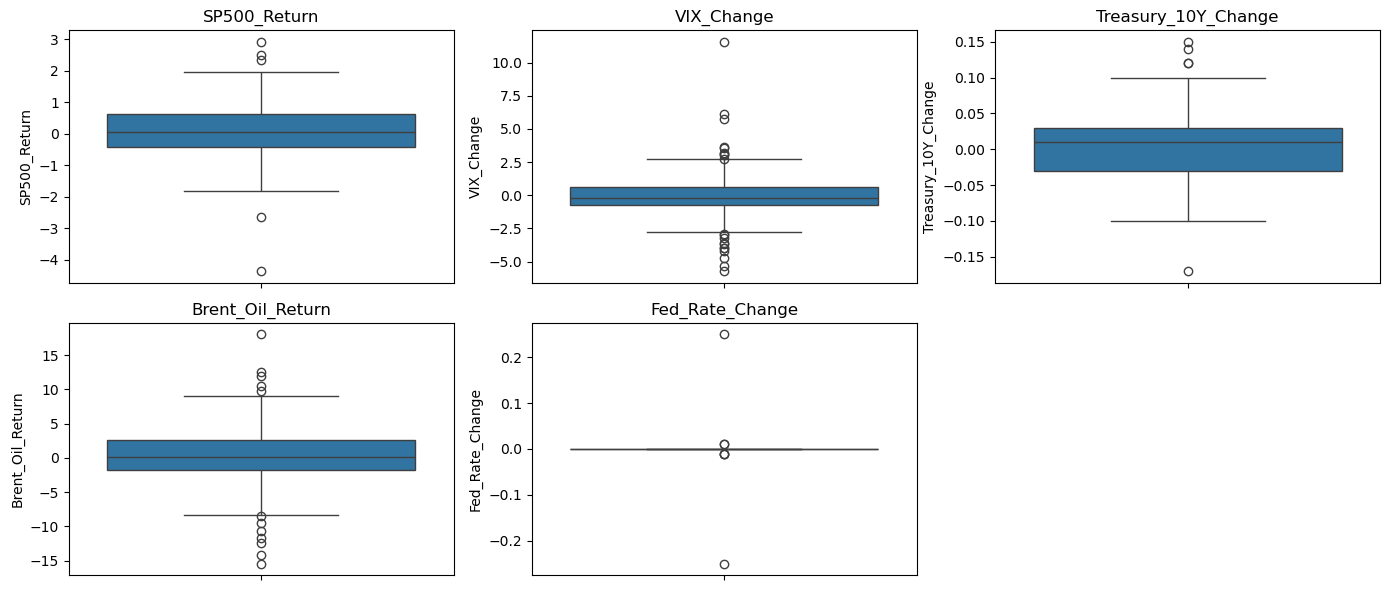

In [28]:
plt.figure(figsize=(14, 6))

for i, col in enumerate(outlier_columns, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_clean[col])
    plt.title(col)

plt.tight_layout()
plt.show()

## 19. Outlier Treatment and Justification

The IQR method was applied to identify potential outliers across the five numerical variables examined. However, these observations were retained without clipping, winsorisation or transformation because extreme values in financial market data may represent genuine market movements rather than data errors.

The decision for each variable is explained below.

### 1. S&P 500 Returns (`SP500_Return`)

- The IQR method identified 149 potential outliers.
- These extreme returns may represent significant movements in the stock market during periods of economic uncertainty, financial crises or major market events.
- Removing or clipping these observations could eliminate important market movements and distort the relationship between S&P 500 returns and the independent variables.
- Therefore, all identified observations were retained.

### 2. VIX Changes (`VIX_Change`)

- The IQR method identified 230 potential outliers.
- The VIX measures expected stock market volatility, and sudden increases or decreases may reflect changes in investor uncertainty and market sentiment.
- These extreme movements are relevant to the study because they may be associated with significant changes in S&P 500 returns.
- Clipping or removing these observations could reduce the ability to examine the relationship between market volatility and stock market returns.
- Therefore, all identified observations were retained.

### 3. Treasury 10-Year Yield Changes (`Treasury_10Y_Change`)

- The IQR method identified 71 potential outliers.
- Large changes in Treasury yields may reflect shifts in interest rate expectations, monetary policy decisions and broader economic conditions.
- These movements are genuine financial observations that may be relevant when examining their association with S&P 500 returns.
- Removing or clipping them could result in the loss of meaningful information.
- Therefore, all identified observations were retained.

### 4. Brent Crude Oil Returns (`Brent_Oil_Return`)

- The IQR method identified 120 potential outliers.
- Significant changes in Brent crude oil prices may occur due to geopolitical developments, supply disruptions, changes in global demand and other economic events.
- These movements may influence broader financial market conditions and are relevant to the analysis.
- Clipping or removing extreme observations could distort the actual behaviour of oil price returns.
- Therefore, all identified observations were retained.

### 5. Federal Reserve Rate Changes (`Fed_Rate_Change`)

- The IQR method identified 234 potential outliers, with both the lower and upper bounds equal to zero.
- This occurred because the distribution of Federal Reserve rate changes contains a high concentration of zero values, representing periods when the Federal Reserve maintained its existing interest rate.
- Consequently, the interquartile range (IQR) was zero, causing the method to classify every non-zero observation as a potential outlier.
- However, these non-zero observations represent actual changes in monetary policy rather than necessarily indicating data errors or statistical anomalies.
- Such changes are economically meaningful because adjustments to the Federal Funds Rate can influence borrowing costs, investment decisions, market expectations and broader financial market conditions.
- Therefore, these observations were retained, and the IQR method was not considered an appropriate basis for removing or modifying them.

### Conclusion

Although the IQR method identified potential outliers across all five variables, these observations were not automatically treated as errors.

For the four continuous financial market variables, extreme observations may contain meaningful information about actual market conditions. For `Fed_Rate_Change`, the zero-width IQR resulted from the concentration of unchanged interest rate observations, making conventional IQR-based outlier identification unsuitable for this variable.

Consequently, no clipping, winsorisation or logarithmic transformation was applied. The original observations were preserved to avoid unnecessarily altering the financial data and potentially distorting the statistical relationships examined in this study.

The possible influence of extreme observations on the regression results will be considered during the statistical analysis.

<h2> 20. Before-and-after comparison </h2>

In [29]:
comparison = pd.DataFrame({
    'Stage': ['Original Dataset', 'Cleaned Dataset'],
    'Rows': [df.shape[0], df_clean.shape[0]],
    'Columns': [df.shape[1], df_clean.shape[1]],
    'Missing Values': [df.isnull().sum().sum(), df_clean.isnull().sum().sum()]
})

comparison

,Stage,Rows,Columns,Missing Values
0,Original Dataset,261,11,111
1,Cleaned Dataset,228,11,0


In [30]:
rows_removed = df.shape[0] - df_clean.shape[0]
retention_rate = (df_clean.shape[0] / df.shape[0]) * 100

print("Rows removed:", rows_removed)
print("Data retention rate:", round(retention_rate, 2), "%")

Rows removed: 33
Data retention rate: 87.36 %


<h2> 21. Final dataset description </h2>

The comparison shows the changes in the dataset following preprocessing. The original dataset contained 2,608 observations and 6 columns. After feature engineering and missing-value handling, the cleaned dataset contains fewer observations and additional columns representing the newly created financial indicators. The missing values in the selected analysis variables have been addressed through complete-case deletion.

<h2> 22. Downloading the cleaned dataset </h2>

In [31]:
cleaned_path = PROCESSED_DATA_DIR / "Financial_dataset_cleaned.csv"

df_clean.to_csv(cleaned_path, index=False)

print("Cleaned dataset saved successfully!")
print("Location:", cleaned_path)

Cleaned dataset saved successfully!
Location: C:\Users\reshma begum\Desktop\Projects\sp500-financial-market-analysis\Data\Processed\Financial_dataset_cleaned.csv
